# Praktikum Week 9 – Kecerdasan Buatan
## Implementasi Neural Network menggunakan Oxford Flowers 102

**Dataset:** Oxford Flowers 102  
**Sumber:** TensorFlow Datasets (TFDS)

Pada notebook ini, dataset Fashion MNIST dari praktikum diganti dengan Oxford Flowers 102. Tahap pengerjaan tetap mengikuti alur praktikum: memuat dataset, preprocessing, membuat model Neural Network, melatih model, mengevaluasi, memvisualisasikan hasil, dan melakukan prediksi.

**Catatan:** Oxford Flowers 102 memiliki 102 kategori bunga. Dataset dibagi menjadi 1.020 gambar training, 1.020 gambar validation, dan 6.149 gambar testing.


## Cell 1 – Instalasi TensorFlow Datasets

Jalankan cell ini jika TensorFlow Datasets belum terpasang. Jika sudah terpasang, pip akan menampilkan pesan `Requirement already satisfied`.


In [1]:
%pip install tensorflow-datasets


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install --upgrade importlib-resources

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Cell 2 – Import Library

Memanggil TensorFlow untuk membuat dan melatih Neural Network, TensorFlow Datasets untuk memuat Oxford Flowers 102, NumPy untuk pengolahan angka, dan Matplotlib untuk visualisasi.


In [3]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt


## Cell 3 – Memuat Dataset Oxford Flowers 102

Dataset dimuat menjadi tiga bagian:
- **Training:** digunakan untuk melatih model.
- **Validation:** digunakan untuk memantau performa model selama training.
- **Testing:** digunakan untuk menguji model setelah training selesai.

`as_supervised=True` membuat dataset menghasilkan pasangan `(gambar, label)`, sedangkan `with_info=True` mengambil informasi dataset.


In [4]:
(train_ds, val_ds, test_ds), info = tfds.load(
    'tf_flowers',
    split=[
        'train[:80%]',
        'train[80%:90%]',
        'train[90%:]'
    ],
    as_supervised=True,
    with_info=True
)

# Menampilkan jumlah data
print("Jumlah data training:", info.splits['train'].num_examples * 0.8)
print("Jumlah kategori:", info.features['label'].num_classes)

Jumlah data training: 2936.0
Jumlah kategori: 5


## Cell 4 – Preprocessing dan Normalisasi Gambar

Gambar Oxford Flowers memiliki ukuran asli yang bervariasi. Agar dapat diproses bersama oleh model, semua gambar diubah menjadi **64 × 64 piksel**.

Nilai piksel kemudian dinormalisasi dari rentang 0–255 menjadi 0–1. Setelah itu, data dikelompokkan dalam batch berisi 32 gambar agar proses training lebih efisien.


In [5]:
# Fungsi untuk mengubah ukuran dan menormalisasi gambar
def preprocess(image, label):
    image = tf.image.resize(image, (64, 64))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Terapkan preprocessing ke setiap bagian dataset
train_ds = train_ds.map(preprocess)
val_ds = val_ds.map(preprocess)
test_ds = test_ds.map(preprocess)

# Mengelompokkan data menjadi batch
train_ds = train_ds.batch(32).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(32).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(32).prefetch(tf.data.AUTOTUNE)

# Mengambil nama 102 kategori bunga
class_names = info.features['label'].names

print("Jumlah nama kategori:", len(class_names))
print("Contoh nama kategori:", class_names[:10])


Jumlah nama kategori: 5
Contoh nama kategori: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


## Cell 5 – Melihat Contoh 25 Gambar

Menampilkan 25 gambar dari data training. Label di bawah setiap gambar menunjukkan nama kategori bunga berdasarkan informasi dataset.


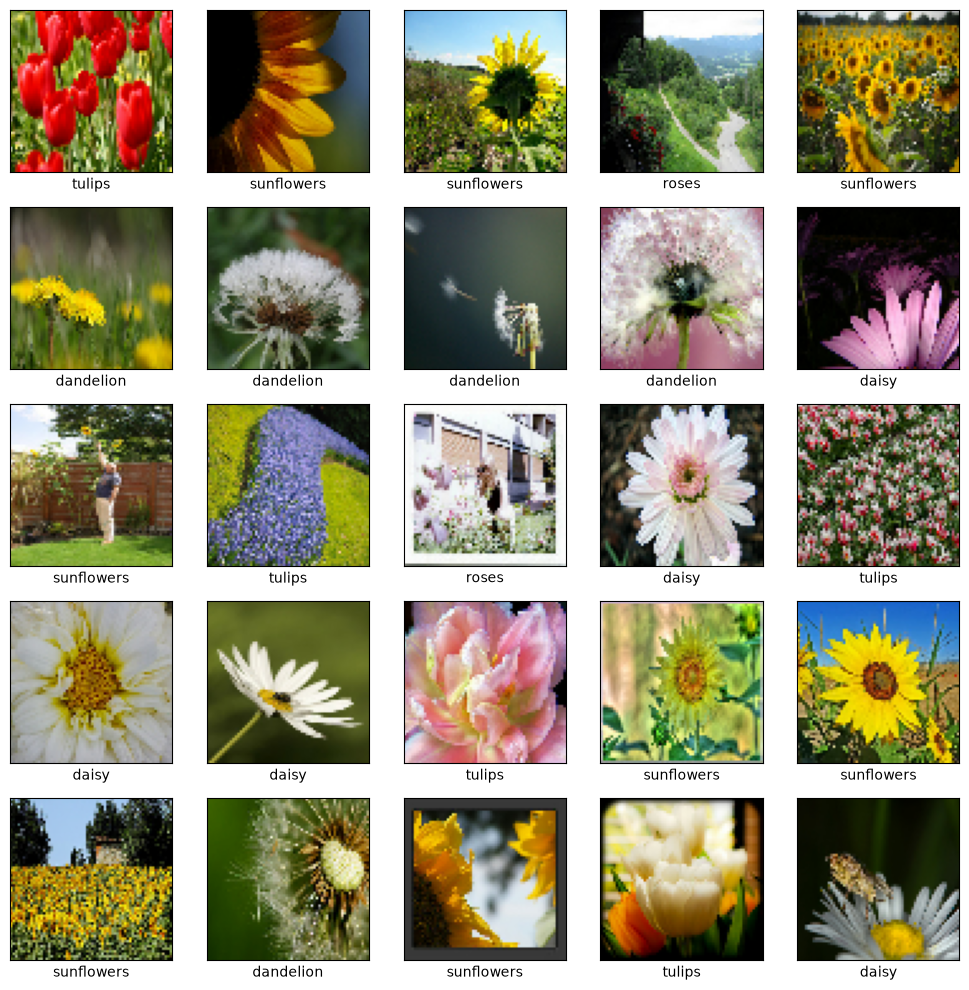

In [6]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i].numpy())
        plt.xlabel(class_names[int(labels[i].numpy())])

plt.tight_layout()
plt.show()


## Cell 6 – Membuat Model Neural Network

Model mengikuti konsep dari praktikum:
- `Flatten`: mengubah gambar menjadi vektor satu dimensi.
- `Dense(128)`: hidden layer dengan 128 neuron dan aktivasi ReLU.
- `Dense(102)`: output layer dengan 102 neuron, sesuai jumlah kategori bunga. Softmax menghasilkan probabilitas untuk setiap kategori.

Karena gambar sekarang berukuran 64 × 64 dan memiliki 3 kanal warna (RGB), bentuk input model adalah `(64, 64, 3)`.


In [7]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

# Membuat model Neural Network
model = Sequential([
    Input(shape=(64, 64, 3)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(102, activation='softmax')
])

# Melihat ringkasan arsitektur model
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 102)            │        13,158 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,586,150 (6.05 MB)

 Trainable params: 1,586,150 (6.05 MB)

 Non-trainable params: 0 (0.00 B)

## Cell 7 – Kompilasi dan Melatih Model

Model menggunakan optimizer Adam, fungsi loss sparse categorical crossentropy, dan metrik accuracy. Model dilatih selama 10 epoch menggunakan data training dan dipantau menggunakan data validation.

Satu epoch berarti model telah melewati seluruh data training satu kali.


In [8]:
# Kompilasi model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Melatih model
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds
)


Epoch 1/10


c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.3505 - loss: 1.9959 - val_accuracy: 0.4496 - val_loss: 1.3482
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4458 - loss: 1.3498 - val_accuracy: 0.4714 - val_loss: 1.3807
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4935 - loss: 1.2495 - val_accuracy: 0.4714 - val_loss: 1.3506
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5283 - loss: 1.1796 - val_accuracy: 0.4768 - val_loss: 1.3521
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.5521 - loss: 1.1271 - val_accuracy: 0.4850 - val_loss: 1.3741
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.5708 - loss: 1.0998 - val_accuracy: 0.4687 - val_loss: 1.4801
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.5695 - loss: 1.1235 - val_accuracy: 0.4632 - val_loss: 1.5804
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.5736 - loss: 1.0707 - val_accuracy: 0.4605 - val_loss: 1.

## Cell 8 – Evaluasi Model

Model diuji menggunakan data testing yang tidak digunakan untuk memperbarui bobot selama training. Hasil evaluasi menampilkan nilai loss dan accuracy pada data testing.


In [9]:
# Evaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(test_ds)

print(f'\nTest loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test accuracy (%): {test_acc * 100:.2f}%')


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4142 - loss: 1.9803

Test loss: 1.9803
Test accuracy: 0.4142
Test accuracy (%): 41.42%


## Cell 9 – Visualisasi Accuracy dan Loss

Grafik accuracy memperlihatkan perubahan ketepatan prediksi selama training dan validation. Grafik loss memperlihatkan perubahan kesalahan model. Grafik ini dapat membantu melihat apakah model belajar dan apakah terdapat indikasi overfitting.


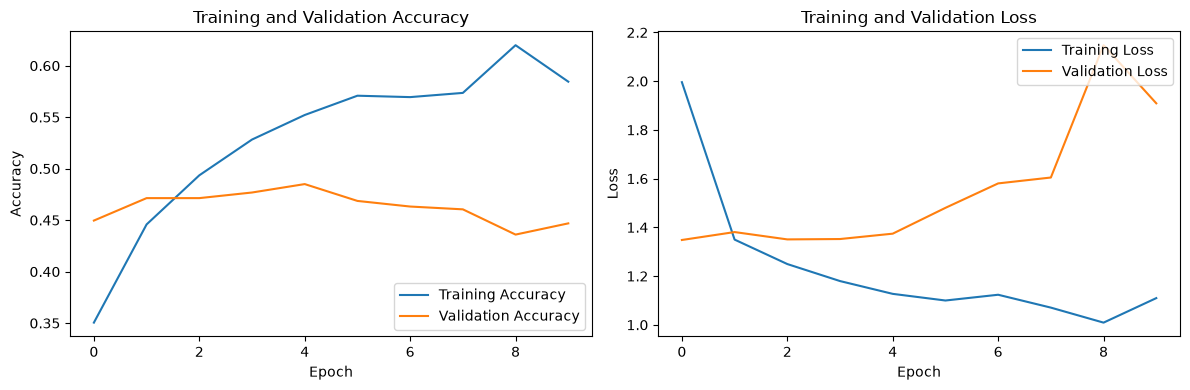

In [10]:
# Fungsi untuk memvisualisasikan accuracy dan loss
def plot_history(history):
    plt.figure(figsize=(12, 4))

    # Grafik accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Grafik loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)


## Cell 10 – Melakukan Prediksi pada Gambar Testing

Model memprediksi kategori untuk satu batch gambar testing. `argmax` memilih indeks kategori dengan probabilitas tertinggi. Hasil prediksi dibandingkan dengan label sebenarnya.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step


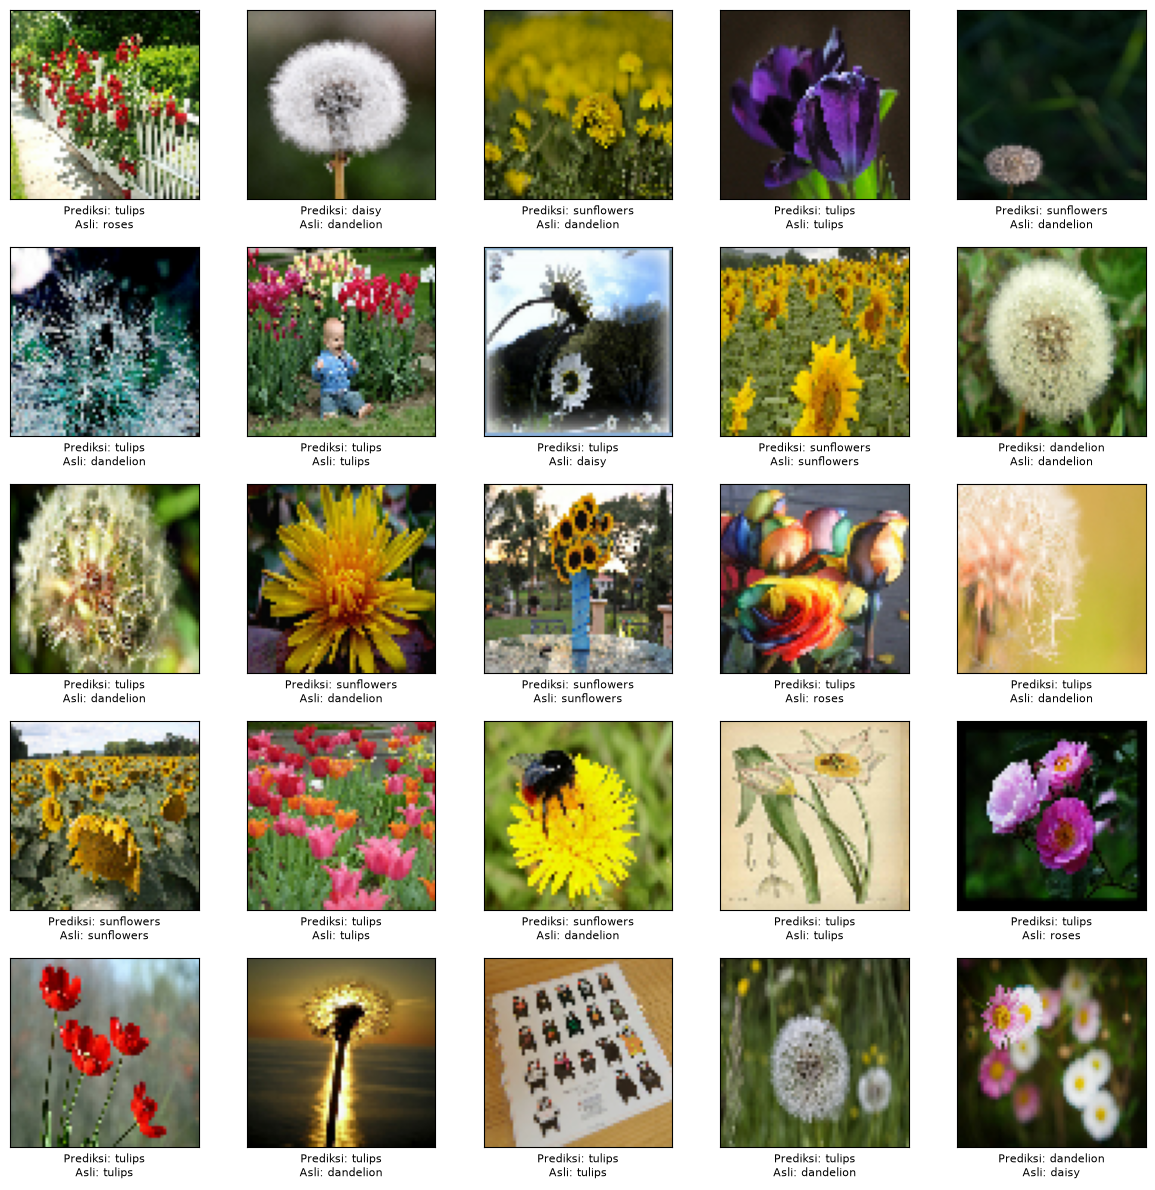

In [11]:
# Mengambil satu batch gambar dari data testing
for test_images, test_labels in test_ds.take(1):
    predictions = model.predict(test_images)

    # Menampilkan maksimal 25 hasil prediksi
    plt.figure(figsize=(12, 12))

    for i in range(min(25, len(test_images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(test_images[i].numpy())

        predicted_label = np.argmax(predictions[i])
        actual_label = int(test_labels[i].numpy())

        predicted_name = class_names[predicted_label]
        actual_name = class_names[actual_label]

        plt.xlabel(
            f"Prediksi: {predicted_name}\nAsli: {actual_name}",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()


## Kesimpulan

Pada praktikum ini, dataset Fashion MNIST diganti dengan Oxford Flowers 102 yang berisi gambar 102 kategori bunga. Program melakukan pemuatan dataset, preprocessing (mengubah ukuran gambar dan normalisasi), visualisasi, pembuatan model Neural Network, training, evaluasi, dan prediksi.

**Catatan:** Model pada notebook ini adalah Neural Network sederhana dengan Flatten dan Dense, mengikuti pola model pada praktikum. Hasil akurasi dapat berbeda pada setiap proses training.
